In [36]:

# ============================================================
# PROJET MIDL 2 - Réseau de neurones avec TensorFlow
# Classification des chiffres manuscrits MNIST
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist




In [37]:
# ------------------------------------------------------------
# 1. Chargement des données
# ------------------------------------------------------------

# Chargement du dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Mettre les pixels entre 0 et 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Transformation des images en vecteurs
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

print("Dimensions X_train :", X_train.shape)
print("Dimensions y_train :", y_train.shape)
print("Dimensions X_test :", X_test.shape)
print("Dimensions y_test :", y_test.shape)

Dimensions X_train : (60000, 784)
Dimensions y_train : (60000,)
Dimensions X_test : (10000, 784)
Dimensions y_test : (10000,)


In [38]:
# ------------------------------------------------------------
# 3. Construction du réseau
# ------------------------------------------------------------
taille_entree = 784
taille_cachee = 128
taille_sortie = 10
model = keras.Sequential([

    # Couche d'entrée
    keras.Input(shape=(taille_entree,)),

    # Couche cachée
    layers.Dense(taille_cachee, activation="relu"),

    # Couche de sortie
    layers.Dense(taille_sortie, activation="softmax")
])


# Couche 1 : 784 -> 128
W1 = np.random.randn(taille_entree, taille_cachee) * np.sqrt(2 / taille_entree)
b1 = np.zeros((128,))

# Couche 2 : 128 -> 10
W2 = np.random.randn(taille_cachee, taille_sortie) * np.sqrt(2 / taille_cachee)
b2 = np.zeros((taille_sortie,))

model.layers[0].set_weights([W1, b1])
model.layers[1].set_weights([W2, b2])

# Affichage de l'architecture
model.summary()



Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# ------------------------------------------------------------
# 4. Configuration de l'apprentissage
# ------------------------------------------------------------

model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [40]:
# ------------------------------------------------------------
# 5. Entraînement du réseau
# ------------------------------------------------------------

history = model.fit(

    X_train,
    y_train,
    epochs=10,
     batch_size=64,
    verbose=1
)


Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8978 - loss: 0.3655
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9431 - loss: 0.1966
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9569 - loss: 0.1491
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9660 - loss: 0.1202
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9717 - loss: 0.1011
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9753 - loss: 0.0871
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9784 - loss: 0.0768
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9809 - loss: 0.0685
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9829 - loss: 0.0614
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9845 - loss: 0.0555


In [46]:
# ------------------------------------------------------------
# 6. évaluation sur les données de test
# ------------------------------------------------------------

test_perte, test_precision = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test perte:", test_perte)
print("Test precision:", test_precision * 100, "%")

Test perte: 0.07739009708166122
Test precision: 97.64999747276306 %


KeyError: 'val_loss'

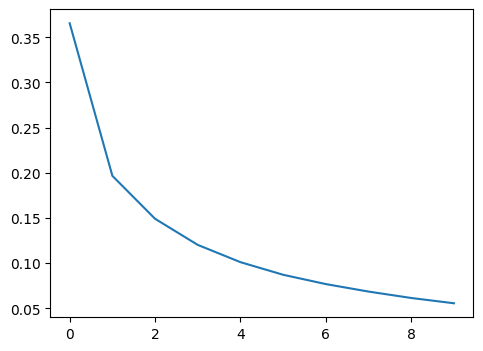

In [43]:
# ------------------------------------------------------------
# 7. Visualisation de l'apprentissage
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

# évolution de la perte
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Entraînement")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Évolution de la Perte (Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

# évolution de la précision
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Entraînement")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Évolution de la précision")
plt.xlabel("Epoques")
plt.ylabel("Précision")
plt.legend()

plt.tight_layout()
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


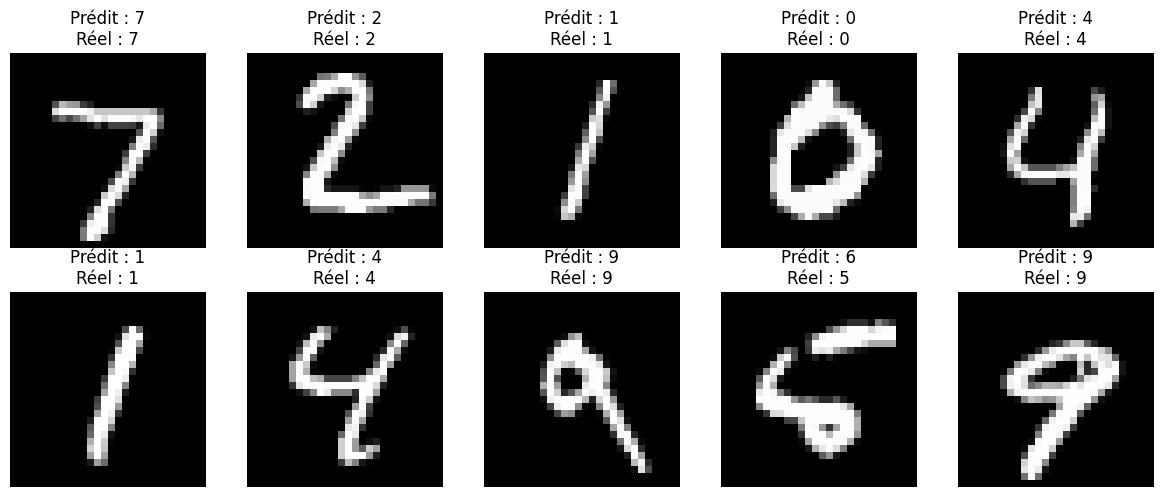

In [45]:
# ------------------------------------------------------------
# 9. Afficher quelques images et leurs prédictions
# ------------------------------------------------------------

# Déclaration des prédictions du modèle pour le jeu de test
predictions = model.predict(X_test)

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    chiffre_predit = np.argmax(predictions[i])
    vrai_chiffre = y_test[i]

    plt.title(f"Prédit : {chiffre_predit}\nRéel : {vrai_chiffre}")

    plt.axis("off")

plt.tight_layout()
plt.show()